# Project U1-U2 · Exploratory Data Analysis of the INEGI Population and Housing Census
## Jalisco, ITER 2010 vs 2020

**Source:** INEGI, Main Results by Locality (ITER), 2010 and 2020 Censuses · [open data](https://www.inegi.org.mx/datosabiertos/)

In [56]:
from pathlib import Path

# Ask for the path of each input file and stop if it does not exist
def pedir_archivo(descripcion):
    ruta = Path(input(f"Path to the {descripcion} file: ").strip().strip('"').strip("'"))
    if not ruta.is_file():
        raise FileNotFoundError(f"File not found: {ruta}")
    return ruta

ARCH_2020 = pedir_archivo("ITER 2020 (conjunto_de_datos_iter_14CSV20.csv)")
ARCH_2010 = pedir_archivo("ITER 2010 (iter_14_cpv2010.csv)")

BASE = Path.cwd()   # outputs are saved here
print("Files:", ARCH_2020.name, "|", ARCH_2010.name)
print("Outputs saved in:", BASE)

Path to the ITER 2020 (conjunto_de_datos_iter_14CSV20.csv) file: /content/conjunto_de_datos_iter_14CSV20.csv
Path to the ITER 2010 (iter_14_cpv2010.csv) file: /content/iter_14_cpv2010.csv
Files: conjunto_de_datos_iter_14CSV20.csv | iter_14_cpv2010.csv
Outputs saved in: /content/drive/MyDrive/Proyecto_ITER_Jalisco


In [57]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
_trapz = getattr(np, "trapezoid", None) or np.trapz   # works with numpy 1.x and 2.x
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


# Part 1 · Data cleaning and preparation

### 1.1 Loading
Files are read as text and column names are standardized so that both census years share the same structure.

In [58]:
DATA_DIR = Path(".")
OUT_DIR = Path("clean_data"); OUT_DIR.mkdir(exist_ok=True)

def cargar_iter(ruta: Path, anio: int) -> pd.DataFrame:
    """Read an ITER file as text and standardize its column names."""
    df = pd.read_csv(ruta, dtype=str, encoding="utf-8-sig")
    # Use lower-case column names in both years
    df.columns = df.columns.str.strip().str.lower()
    # Align column names that differ between censuses
    df = df.rename(columns={"tamloc": "tam_loc"})
    df["anio"] = anio
    return df

### 1.2 Geographic levels
The ITER tables mix state, municipal and locality records. This step separates them so that only real localities are analyzed and no population is counted twice.

In [59]:
def separar_niveles(df: pd.DataFrame) -> dict:
    """Split the table into state, municipal, subtotal and locality records."""
    mun = df["mun"].astype(int)
    loc = df["loc"].astype(int)

    es_entidad = (mun == 0) & (loc == 0)
    es_municipio = (mun != 0) & (loc == 0)
    es_peq = loc.isin([9998, 9999])
    es_localidad = (mun != 0) & ~loc.isin([0, 9998, 9999])

    return {
        "state": df[es_entidad].copy(),
        "municipalities": df[es_municipio].copy(),
        "small_locality_subtotals": df[es_peq & (mun != 0)].copy(),
        "localities": df[es_localidad].copy(),
    }

### 1.3 Missing values and coordinates
Special codes for confidential or unavailable data are treated as missing values, and coordinates are converted to decimal degrees.

In [60]:
def a_numerico(df: pd.DataFrame) -> pd.DataFrame:
    """Turn special codes into missing values and the remaining columns into numbers."""
    df = df.copy()
    df = df.replace({"*": np.nan, "N/D": np.nan})
    excluir = {"nom_ent", "nom_mun", "nom_loc", "longitud", "latitud"}
    for c in df.columns:
        if c not in excluir:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df


def dms_a_decimal(valor, anio):
    """Convert census coordinates to decimal degrees (formats differ by year)."""
    if pd.isna(valor):
        return np.nan
    s = str(valor).strip()
    if anio == 2020:
        m = re.match(r"(\d+)°(\d+)'([\d.]+)\"\s*([NSEW])", s)
        if not m:
            return np.nan
        g, mi, se, h = m.groups()
        dec = float(g) + float(mi) / 60 + float(se) / 3600
        return -dec if h in "WS" else dec
    # 2010 format
    s = s.zfill(6)
    g, mi, se = int(s[:-4]), int(s[-4:-2]), int(s[-2:])
    return g + mi / 60 + se / 3600


def agregar_coordenadas(df: pd.DataFrame, anio: int) -> pd.DataFrame:
    df = df.copy()
    df["lat"] = df["latitud"].apply(lambda v: dms_a_decimal(v, anio))
    df["lon"] = df["longitud"].apply(lambda v: dms_a_decimal(v, anio))
    if anio == 2010:              # 2010 longitudes are stored without sign
        df["lon"] = -df["lon"]
    return df

### 1.4 Validation
The population of all localities must match the official total of each municipality.

In [61]:
def validar(niveles: dict, anio: int) -> pd.DataFrame:
    """Compare the sum of localities with the official municipal totals."""
    suma = niveles["localities"].groupby("mun")["pobtot"].sum()
    duplicado = niveles["small_locality_subtotals"]["pobtot"].sum()
    oficial = niveles["municipalities"].set_index("mun")["pobtot"]
    chk = pd.DataFrame({"sum_of_localities": suma, "official_total": oficial})
    chk["difference"] = chk["official_total"] - chk["sum_of_localities"]

    total_ent = niveles["state"]["pobtot"].iloc[0]
    print(f"[{anio}] State population: {total_ent:,.0f} | "
          f"sum of municipalities: {oficial.sum():,.0f} | "
          f"municipalities that do not match: {(chk['difference'] != 0).sum()} | "
          f"population double counted if subtotals were added: {duplicado:,.0f}")
    return chk


def procesar(ruta: Path, anio: int):
    crudo = cargar_iter(ruta, anio)
    n_ast = (crudo == "*").sum().sum()
    n_nd = (crudo == "N/D").sum().sum()
    print(f"\n[{anio}] {crudo.shape[0]:,} rows x {crudo.shape[1]} columns | "
          f"'*' cells: {n_ast:,} | 'N/D' cells: {n_nd:,}")

    niveles = {k: a_numerico(v) for k, v in separar_niveles(crudo).items()}
    for k, v in niveles.items():
        print(f"   {k:<26} {len(v):>6,} rows")

    niveles["localities"] = agregar_coordenadas(niveles["localities"], anio)
    validar(niveles, anio)
    return niveles

In [62]:
n20 = procesar(ARCH_2020, 2020)
n10 = procesar(ARCH_2010, 2010)


[2020] 10,715 rows x 287 columns | '*' cells: 1,157,292 | 'N/D' cells: 4,336
   state                           1 rows
   municipalities                125 rows
   small_locality_subtotals      239 rows
   localities                 10,348 rows
[2020] State population: 8,348,151 | sum of municipalities: 8,348,151 | municipalities that do not match: 0 | population double counted if subtotals were added: 23,529

[2010] 11,314 rows x 201 columns | '*' cells: 881,342 | 'N/D' cells: 0
   state                           1 rows
   municipalities                125 rows
   small_locality_subtotals      240 rows
   localities                 10,946 rows
[2010] State population: 7,350,682 | sum of municipalities: 7,350,682 | municipalities that do not match: 0 | population double counted if subtotals were added: 27,851


### 1.5 Indicators
Counts are converted into rates so that places of different size can be compared. Housing indicators use occupied dwellings with recorded characteristics as the denominator.

In [63]:
def pct(num, den):
    """Percentage that returns NaN when the denominator is zero or missing."""
    den = den.where(den > 0)
    return (num / den * 100).round(2)


def construir_indicadores(df: pd.DataFrame) -> pd.DataFrame:
    """Build rates that are comparable between both census years."""
    out = df[["anio", "mun", "nom_mun", "loc", "nom_loc"]].copy()
    if "lat" in df:
        out[["lat", "lon", "altitud"]] = df[["lat", "lon", "altitud"]]

    viv = df["vivparh_cv"] if "vivparh_cv" in df else df["vivpar_hab"]
    out["pobtot"] = df["pobtot"]
    out["viv_denominador"] = viv

    # --- Demography
    out["pct_0a14"] = pct(df["pob0_14"], df["pobtot"])
    out["pct_65ymas"] = pct(df["pob65_mas"], df["pobtot"])
    out["indice_envejecimiento"] = pct(df["pob65_mas"], df["pob0_14"])  # 65+ per 100 children
    out["razon_dependencia"] = pct(df["pob0_14"] + df["pob65_mas"], df["pob15_64"])
    out["rel_h_m"] = df["rel_h_m"]
    out["prom_hnv"] = df["prom_hnv"]
    out["pct_nacido_otra_ent"] = pct(df["pnacoe"], df["pobtot"])
    out["pct_hli"] = pct(df["p3ym_hli"], df["p_3ymas"])

    # --- Education
    out["graproes"] = df["graproes"]
    out["pct_analfabeta_15ym"] = pct(df["p15ym_an"], df["p_15ymas"])
    out["pct_sin_escol_15ym"] = pct(df["p15ym_se"], df["p_15ymas"])
    out["pct_posbasica_18ym"] = pct(df["p18ym_pb"], df["p_18ymas"])
    out["pct_asiste_15a17"] = pct(df["p15a17a"], df["p_15a17"])

    # --- Economy
    out["tasa_participacion"] = pct(df["pea"], df["p_12ymas"])
    out["tasa_desocupacion"] = pct(df["pdesocup"], df["pea"])
    out["pct_pea_mujeres"] = pct(df["pea_f"], df["pea"])

    # --- Health
    out["pct_sin_derechohab"] = pct(df["psinder"], df["pobtot"])
    out["pct_imss"] = pct(df["pder_imss"], df["pobtot"])

    # --- Households
    out["pct_hog_jef_fem"] = pct(df["hogjef_f"], df["tothog"])
    out["prom_ocup"] = df["prom_ocup"]
    out["pro_ocup_c"] = df["pro_ocup_c"]
    out["pct_viv_deshab"] = pct(df["vivpar_des"], df["tvivpar"])

    # --- Housing and services
    out["pct_piso_tierra"] = pct(df["vph_pisoti"], viv)
    out["pct_1cuarto"] = pct(df["vph_1cuart"], viv)
    out["pct_electricidad"] = pct(df["vph_c_elec"], viv)
    out["pct_agua_entubada"] = pct(df["vph_aguadv"], viv)
    out["pct_drenaje"] = pct(df["vph_drenaj"], viv)
    out["pct_3servicios"] = pct(df["vph_c_serv"], viv)

    # --- Household assets and ICT
    out["pct_refri"] = pct(df["vph_refri"], viv)
    out["pct_lavadora"] = pct(df["vph_lavad"], viv)
    out["pct_auto"] = pct(df["vph_autom"], viv)
    out["pct_pc"] = pct(df["vph_pc"], viv)
    out["pct_tel_fijo"] = pct(df["vph_telef"], viv)
    out["pct_celular"] = pct(df["vph_cel"], viv)
    out["pct_internet"] = pct(df["vph_inter"], viv)
    out["pct_sin_bienes"] = pct(df["vph_snbien"], viv)

    # --- Locality type and size
    out["ambito"] = np.where(df["pobtot"] >= 2500, "Urban", "Rural")
    out["rango_tam"] = pd.cut(
        df["pobtot"],
        bins=[0, 99, 499, 2_499, 14_999, 99_999, np.inf],
        labels=["1-99", "100-499", "500-2,499", "2,500-14,999",
                "15,000-99,999", "100,000+"])
    return out

In [64]:
ind_loc = pd.concat([construir_indicadores(n10["localities"]),
                     construir_indicadores(n20["localities"])],
                    ignore_index=True)
ind_mun = pd.concat([construir_indicadores(n10["municipalities"]),
                     construir_indicadores(n20["municipalities"])],
                    ignore_index=True).drop(columns=["loc", "nom_loc", "ambito", "rango_tam"])
ind_ent = pd.concat([construir_indicadores(n10["state"]),
                     construir_indicadores(n20["state"])],
                    ignore_index=True)

# Municipal panel: one row per municipality with 2010-2020 changes
panel = ind_mun.pivot(index=["mun"], columns="anio")
panel.columns = [f"{v}_{a}" for v, a in panel.columns]
panel = panel.rename(columns={"nom_mun_2020": "nom_mun"}).drop(columns="nom_mun_2010")
for v in ["pct_internet", "pct_pc", "pct_celular", "pct_sin_derechohab",
          "pct_65ymas", "graproes", "pct_piso_tierra", "pct_3servicios"]:
    panel[f"delta_{v}"] = (panel[f"{v}_2020"] - panel[f"{v}_2010"]).round(2)
panel["crec_pob_pct"] = pct(panel["pobtot_2020"] - panel["pobtot_2010"], panel["pobtot_2010"])

print("Localities:", ind_loc.shape, "| Municipalities:", ind_mun.shape, "| State:", ind_ent.shape)
assert (ind_loc.filter(like="pct_") > 100.01).sum().sum() == 0, "Rates above 100%"
ind_ent[["anio", "pobtot", "pct_65ymas", "graproes", "pct_sin_derechohab",
         "pct_3servicios", "pct_pc", "pct_celular", "pct_internet"]]

Localities: (21294, 48) | Municipalities: (250, 41) | State: (2, 45)


,anio,pobtot,pct_65ymas,graproes,pct_sin_derechohab,pct_3servicios,pct_pc,pct_celular,pct_internet
0,2010,7350682,6.27,8.78,34.51,92.59,36.19,75.38,27.02
1,2020,8348151,8.22,9.90,29.38,97.96,44.46,91.69,61.75


### 1.6 Export clean tables

In [65]:
ind_loc.to_csv(OUT_DIR / "locality_indicators_2010_2020.csv", index=False)
ind_mun.to_csv(OUT_DIR / "municipal_indicators_2010_2020.csv", index=False)
ind_ent.to_csv(OUT_DIR / "state_indicators_2010_2020.csv", index=False)
panel.reset_index().to_csv(OUT_DIR / "municipal_panel_2010_2020.csv", index=False)

print("Missing values in 2020 localities (% of rows, top 8):")
print((ind_loc[ind_loc.anio == 2020].isna().mean() * 100).sort_values(ascending=False).head(8).round(1).to_string())
print("\nFiles saved in:", OUT_DIR.resolve())

Missing values in 2020 localities (% of rows, top 8):
pct_asiste_15a17         53.4
indice_envejecimiento    43.3
tasa_desocupacion        42.0
pct_pea_mujeres          42.0
pct_viv_deshab           41.0
rel_h_m                  41.0
prom_hnv                 41.0
razon_dependencia        41.0

Files saved in: /content/drive/MyDrive/Proyecto_ITER_Jalisco/clean_data


# Part 2 · Exploratory Data Analysis

### 2.0 Setup
Visual style, helper functions and the clean tables. Each figure and table below appears in the report; figures are displayed and saved to `figures/`, tables to `tables/`.

In [66]:
from matplotlib.patches import Patch

DATA = OUT_DIR
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
TAB = Path("tables"); TAB.mkdir(exist_ok=True)

INK, INK2, GRID = "#141414", "#52514e", "#e4e3df"
IND = {  # key: (label, solid 2020, light 2010)
    "pct_electricidad":  ("Electricity",           "#eda100", "#f6dc9c"),
    "pct_agua_entubada": ("Piped water",            "#2a78d6", "#b7d3f6"),
    "pct_drenaje":       ("Drainage",               "#1baf7a", "#b4e6d2"),
    "pct_3servicios":    ("All three services",     "#0d366b", "#9ec5f4"),
    "pct_piso_firme":    ("Non-dirt floor",         "#eb6834", "#f8c9b2"),
    "pct_internet":      ("Internet",               "#6250d6", "#cfc9f3"),
}
ORA = LinearSegmentedColormap.from_list("o", ["#fbe9df", "#f4a37f", "#eb6834", "#b5461a", "#6e2a0f"])
BLU = LinearSegmentedColormap.from_list("b", ["#e3eefc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
NORTE = {"Bolaños", "Chimaltitán", "Colotlán", "Huejúcar", "Huejuquilla el Alto", "Mezquitic",
         "San Martín de Bolaños", "Santa María de los Ángeles", "Totatiche", "Villa Guerrero"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9.5,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})


def guardar(fig, nombre, mostrar=True):
    fig.savefig(FIG / nombre)
    plt.show() if mostrar else plt.close(fig)
    print("  figure:", nombre)


def reparar(s):
    def fix(x):
        if isinstance(x, str) and "Ã" in x:
            try:
                return x.encode("latin-1").decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                return x
        return x
    return s.map(fix)


def wavg(g, col, w="viv_denominador"):
    m = g[col].notna() & g[w].notna()
    return np.average(g.loc[m, col], weights=g.loc[m, w]) if m.any() else np.nan

In [67]:
ent = pd.read_csv(DATA / "state_indicators_2010_2020.csv")
mun = pd.read_csv(DATA / "municipal_indicators_2010_2020.csv")
loc = pd.read_csv(DATA / "locality_indicators_2010_2020.csv")
for d in (mun, loc):
    d["nom_mun"] = reparar(d["nom_mun"])
for d in (ent, mun, loc):
    d["pct_piso_firme"] = 100 - d["pct_piso_tierra"]

# % of each municipality's population living in rural localities (< 2,500)
rur = (loc.assign(pob_rural=np.where(loc.pobtot < 2500, loc.pobtot, 0))
          .groupby(["anio", "mun"])[["pob_rural", "pobtot"]].sum())
rur["pct_pob_rural"] = rur.pob_rural / rur.pobtot * 100
mun = mun.merge(rur[["pct_pob_rural"]].reset_index(), on=["anio", "mun"], how="left")
m10, m20 = mun[mun.anio == 2010].set_index("mun"), mun[mun.anio == 2020].set_index("mun")
V = list(IND)

### Table 1 · Descriptive statistics
Coverage indicators across the 125 municipalities in each year.

In [68]:
rows = []
for v in V:
    for a, m in ((2010, m10), (2020, m20)):
        s = m[v].dropna()
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        rows.append({"indicator": IND[v][0], "year": a, "state_rate": ent.set_index("anio").loc[a, v],
                     "mean": s.mean(), "median": s.median(), "sd": s.std(), "cv": s.std() / s.mean(),
                     "min": s.min(), "max": s.max(), "skew": s.skew(),
                     "iqr_outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                     "n_below_90": int((s < 90).sum())})
t1 = pd.DataFrame(rows).round(2)
t1.to_csv(TAB / "table1_descriptive_municipal.csv", index=False)
print(t1.to_string(index=False))

         indicator  year  state_rate  mean  median    sd   cv   min   max  skew  iqr_outliers  n_below_90
       Electricity  2010       98.89 96.65   98.45  6.11 0.06 51.74 99.68 -5.20            12           7
       Electricity  2020       99.03 98.67   99.49  3.27 0.03 70.33 99.94 -6.80            14           2
       Piped water  2010       94.17 90.59   94.04  9.03 0.10 51.35 98.98 -2.11            11          35
       Piped water  2020       98.66 98.21   99.03  3.20 0.03 70.77 99.89 -6.17            10           2
          Drainage  2010       97.34 92.68   95.56  9.48 0.10 32.86 99.36 -3.90             8          24
          Drainage  2020       98.59 97.06   98.65  6.59 0.07 40.35 99.81 -6.51            11           5
All three services  2010       92.59 85.91   89.83 12.07 0.14 27.78 98.67 -2.23             9          64
All three services  2020       97.96 95.78   97.58  7.17 0.07 37.23 99.55 -5.82            14           7
    Non-dirt floor  2010       96.98 95.11   9

### Figure 1 · Statewide trend
Statewide coverage in 2010 and 2020.

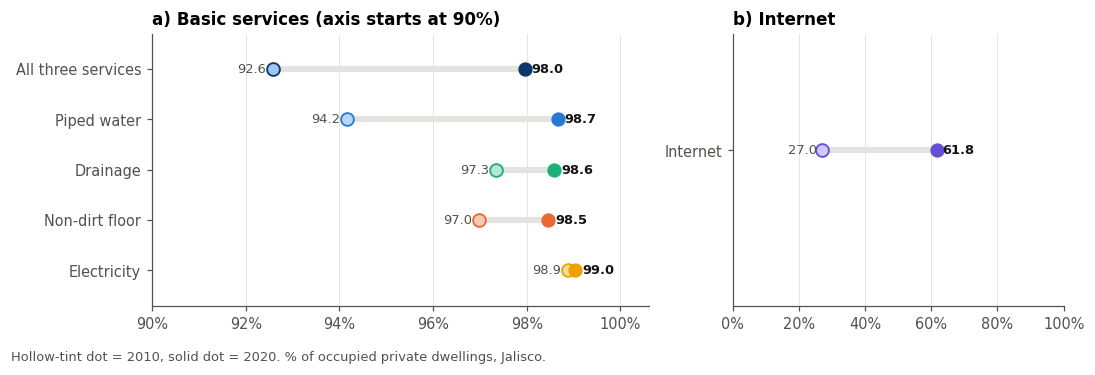

  figure: fig1_statewide_trend.png


In [69]:
e = ent.set_index("anio")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
basic = ["pct_3servicios", "pct_agua_entubada", "pct_drenaje", "pct_piso_firme", "pct_electricidad"]
for ax, vs, lim in ((ax1, basic, (90, 100.6)), (ax2, ["pct_internet"], (0, 100))):
    for i, v in enumerate(vs):
        lab, c20, c10 = IND[v]
        a, b = e.loc[2010, v], e.loc[2020, v]
        ax.plot([a, b], [i, i], color=GRID, lw=4, zorder=1, solid_capstyle="round")
        ax.scatter(a, i, s=70, color=c10, edgecolor=c20, lw=1.2, zorder=2)
        ax.scatter(b, i, s=70, color=c20, zorder=3)
        ax.text(a - (0.15 if lim[0] else 1.5), i, f"{a:.1f}", ha="right", va="center", fontsize=8.5, color=INK2)
        ax.text(b + (0.15 if lim[0] else 1.5), i, f"{b:.1f}", ha="left", va="center", fontsize=8.5,
                color=INK, fontweight="bold")
    ax.set_yticks(range(len(vs)), [IND[v][0] for v in vs])
    ax.set_xlim(*lim); ax.set_ylim(-0.7, len(vs) - 0.3); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.grid(axis="y", visible=False)
ax1.set_title("a) Basic services (axis starts at 90%)")
ax2.set_title("b) Internet"); ax2.set_ylim(-1.2, 0.9)
fig.text(0.01, -0.04, "Hollow-tint dot = 2010, solid dot = 2020. % of occupied private dwellings, Jalisco.",
         fontsize=8.5, color=INK2)
fig.tight_layout()
guardar(fig, "fig1_statewide_trend.png")

### Figure 2 · Coverage by locality size
Dwelling-weighted coverage by locality size, and the rural–urban gap.

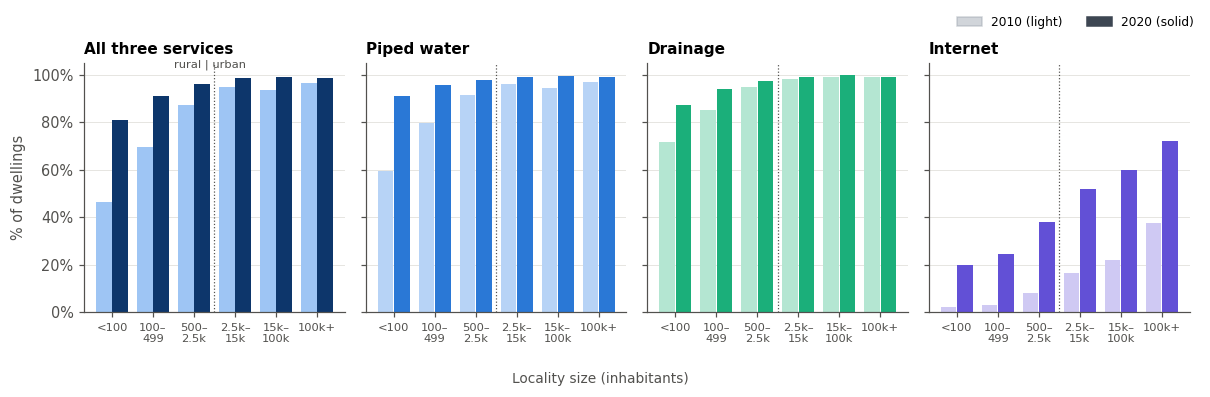

  figure: fig2_coverage_by_locality_size.png
         indicator  year  rural  urban  gap_pp
       Electricity  2010   96.0   99.5     3.4
       Electricity  2020   97.9   99.2     1.3
       Piped water  2010   83.1   96.1    13.0
       Piped water  2020   96.3   99.0     2.8
          Drainage  2010   88.4   98.8    10.5
          Drainage  2020   95.0   99.1     4.2
All three services  2010   75.9   95.4    19.5
All three services  2020   92.5   98.8     6.2
    Non-dirt floor  2010   94.5   97.4     2.9
    Non-dirt floor  2020   96.3   98.8     2.5
          Internet  2010    5.6   30.4    24.9
          Internet  2020   31.6   65.8    34.2


In [70]:
orden = ["1-99", "100-499", "500-2,499", "2,500-14,999", "15,000-99,999", "100,000+"]
etq = ["<100", "100–\n499", "500–\n2.5k", "2.5k–\n15k", "15k–\n100k", "100k+"]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.3), sharey=True)
t_size = []
for ax, v in zip(axes, ["pct_3servicios", "pct_agua_entubada", "pct_drenaje", "pct_internet"]):
    lab, c20, c10 = IND[v]
    for k, (a, col) in enumerate(((2010, c10), (2020, c20))):
        d = loc[loc.anio == a]
        vals = [wavg(d[d.rango_tam == r], v) for r in orden]
        ax.bar(np.arange(6) + (k - .5) * .4, vals, .38, color=col, label=str(a))
        t_size += [{"indicator": lab, "year": a, "size": r, "rate": round(x, 1)} for r, x in zip(orden, vals)]
    ax.set_xticks(range(6), etq, fontsize=7.5)
    ax.set_title(lab, fontsize=10); ax.grid(axis="x", visible=False)
    ax.axvline(2.5, color=INK2, ls=":", lw=0.8)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_ylabel("% of dwellings")
fig.legend(handles=[Patch(color="#9aa3ad", alpha=.45, label="2010 (light)"), Patch(color="#3d4652", label="2020 (solid)")],
           loc="upper right", ncol=2, fontsize=8, bbox_to_anchor=(1, 1.06))
axes[0].text(2.4, 103, "rural | urban", ha="center", fontsize=7.5, color=INK2)
fig.supxlabel("Locality size (inhabitants)", fontsize=9, color=INK2)
fig.tight_layout()
guardar(fig, "fig2_coverage_by_locality_size.png")
pd.DataFrame(t_size).pivot_table(index=["indicator", "size"], columns="year", values="rate", sort=False) \
    .to_csv(TAB / "coverage_by_locality_size.csv")

# rural vs urban gaps
gaps = []
for v in V:
    for a in (2010, 2020):
        d = loc[loc.anio == a]
        r, u = wavg(d[d.pobtot < 2500], v), wavg(d[d.pobtot >= 2500], v)
        gaps.append({"indicator": IND[v][0], "year": a, "rural": r, "urban": u, "gap_pp": u - r})
gaps = pd.DataFrame(gaps).round(1)
gaps.to_csv(TAB / "rural_urban_gap.csv", index=False)
print(gaps.to_string(index=False))

### Figure 3 · Municipal distribution and convergence
Distribution of municipal coverage and its relation to the starting level.

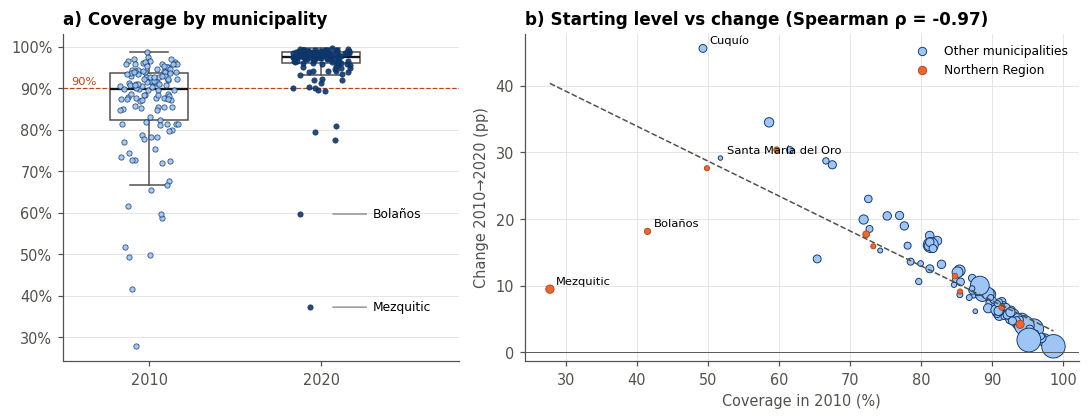

  figure: fig3_municipal_distribution_convergence.png


In [71]:
v = "pct_3servicios"; lab, c20, c10 = IND[v]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1, 1.4]})
rng = np.random.default_rng(1)
for k, (m, col, edge) in enumerate(((m10, c10, c20), (m20, c20, c20))):
    s = m[v].dropna()
    ax1.boxplot(s, positions=[k], widths=.45, showfliers=False, patch_artist=True,
                boxprops=dict(facecolor="none", edgecolor=INK2), medianprops=dict(color=INK, lw=1.5),
                whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    ax1.scatter(k + rng.uniform(-.17, .17, len(s)), s, s=12, color=col, edgecolor=edge, lw=.5, alpha=.9, zorder=3)
for name in ("Mezquitic", "Bolaños"):
    y = m20.loc[m20.nom_mun == name, v].iloc[0]
    ax1.annotate(name, (1.05, y), xytext=(1.3, y), fontsize=8, va="center",
                 arrowprops=dict(arrowstyle="-", color=INK2, lw=.6))
ax1.axhline(90, color="#b5461a", ls="--", lw=.8)
ax1.text(-.45, 91, "90%", fontsize=7.5, color="#b5461a")
ax1.set_xticks([0, 1], ["2010", "2020"]); ax1.set_xlim(-.5, 1.8)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax1.grid(axis="x", visible=False)
ax1.set_title("a) Coverage by municipality")

x0, dl = m10[v], m20[v] - m10[v]
rho = x0.corr(dl, method="spearman")
nor = m20.nom_mun.isin(NORTE)
ax2.scatter(x0[~nor], dl[~nor], s=np.sqrt(m20.pobtot[~nor]) / 5, color=c10, edgecolor=c20, lw=.6, label="Other municipalities")
ax2.scatter(x0[nor], dl[nor], s=np.sqrt(m20.pobtot[nor]) / 5, color="#eb6834", edgecolor="#b5461a", lw=.6, label="Northern Region")
b1, b0 = np.polyfit(x0, dl, 1); xs = np.linspace(x0.min(), x0.max(), 50)
ax2.plot(xs, b0 + b1 * xs, color=INK2, lw=1, ls="--")
ax2.axhline(0, color=INK2, lw=.6)
for name in ("Mezquitic", "Bolaños", "Santa María del Oro", "Cuquío"):
    i = m20.index[m20.nom_mun == name][0]
    ax2.annotate(name, (x0[i], dl[i]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)
ax2.set_xlabel("Coverage in 2010 (%)"); ax2.set_ylabel("Change 2010→2020 (pp)")
ax2.set_title(f"b) Starting level vs change (Spearman ρ = {rho:.2f})"); ax2.legend(fontsize=8, loc="upper right", markerscale=.6)
for h in ax2.get_legend().legend_handles: h.set_sizes([30])
fig.tight_layout()
guardar(fig, "fig3_municipal_distribution_convergence.png")

### Figure 4 · Lowest-coverage municipalities
The 15 municipalities with the lowest coverage in 2020.

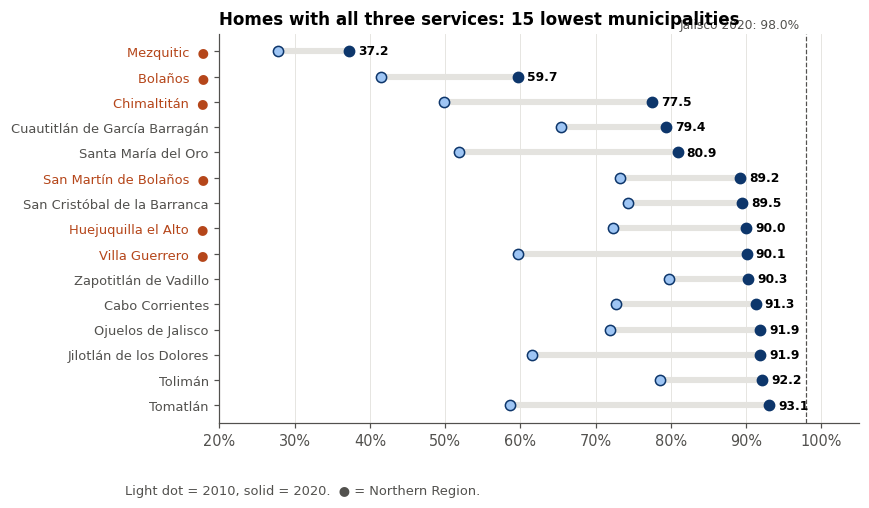

  figure: fig4_lowest_municipalities.png


In [72]:
low = m20.nsmallest(15, v)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for i, (idx, r) in enumerate(low.iterrows()):
    a, b = m10.loc[idx, v], r[v]
    ax.plot([a, b], [i, i], color=GRID, lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(a, i, s=45, color=c10, edgecolor=c20, lw=1, zorder=2)
    ax.scatter(b, i, s=45, color=c20, zorder=3)
    ax.text(b + 1.2, i, f"{np.round(b + 1e-9, 1):.1f}", va="center", fontsize=8, fontweight="bold")
ax.set_yticks(range(15), [n + ("  ●" if n in NORTE else "") for n in low.nom_mun], fontsize=8.5)
for t in ax.get_yticklabels():
    if t.get_text().endswith("●"):
        t.set_color("#b5461a")
ax.invert_yaxis(); ax.set_xlim(20, 105); ax.grid(axis="y", visible=False)
ax.axvline(e.loc[2020, v], color=INK2, ls="--", lw=.8)
ax.text(e.loc[2020, v] - 0.8, -0.9, f"Jalisco 2020: {e.loc[2020, v]:.1f}%", ha="right", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Homes with all three services: 15 lowest municipalities")
fig.text(0.01, -0.03, "Light dot = 2010, solid = 2020.  ● = Northern Region.", fontsize=8.5, color=INK2)
guardar(fig, "fig4_lowest_municipalities.png")

### Figures 5 and 6 · Hexagon maps
Basic-service deficit in 2020 and internet access in 2010 and 2020.

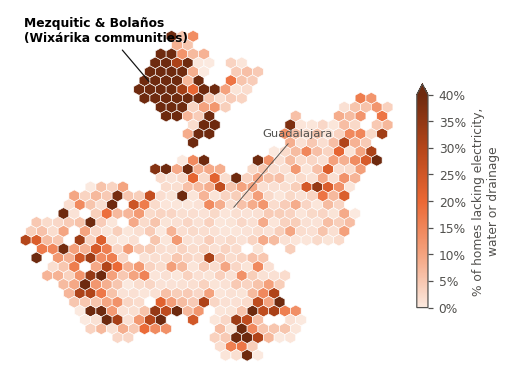

  figure: fig5_map_deficit_2020.png


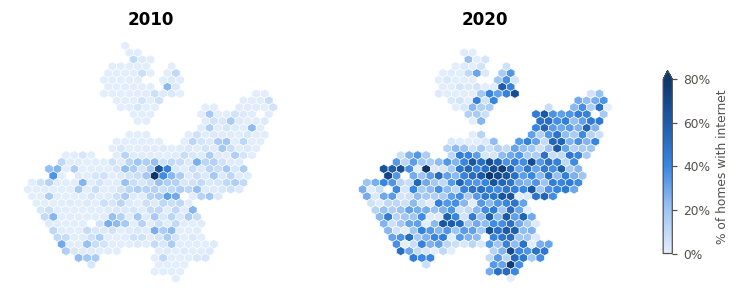

  figure: fig6_map_internet.png


In [73]:
def hexmap(ax, d, val, cmap, vmin, vmax, ext, gs=34):
    d = d.dropna(subset=["lat", "lon", val, "viv_denominador"])
    w = d.viv_denominador.values
    h1 = ax.hexbin(d.lon, d.lat, C=d[val].values * w / 100, reduce_C_function=np.sum, gridsize=gs, extent=ext)
    h2 = ax.hexbin(d.lon, d.lat, C=w, reduce_C_function=np.sum, gridsize=gs, extent=ext)
    a1, a2 = h1.get_array(), h2.get_array(); h1.remove()
    h2.set_array(np.ma.masked_invalid(np.where(a2 >= 3, a1 / np.maximum(a2, 1) * 100, np.nan)))
    h2.set_cmap(cmap); h2.set_clim(vmin, vmax); h2.set_edgecolor("white"); h2.set_linewidth(.4)
    ax.set_aspect("equal"); ax.axis("off")
    return h2


allp = loc.dropna(subset=["lat", "lon"])
ext = (allp.lon.min() - .05, allp.lon.max() + .05, allp.lat.min() - .05, allp.lat.max() + .05)
d20 = loc[loc.anio == 2020].copy(); d20["deficit"] = 100 - d20.pct_3servicios
fig, ax = plt.subplots(figsize=(5.6, 4.8))
hb = hexmap(ax, d20, "deficit", ORA, 0, 40, ext)
c = d20[(d20.nom_mun.isin(["Mezquitic", "Bolaños"])) & (d20.deficit > 50)]
cx, cy = np.average(c.lon, weights=c.viv_denominador), np.average(c.lat, weights=c.viv_denominador)
ax.annotate("Mezquitic & Bolaños\n(Wixárika communities)", (cx - .15, cy + .05), xytext=(-105.75, 22.75),
            fontsize=8, fontweight="bold", va="center", arrowprops=dict(arrowstyle="-", color=INK, lw=.8))
gd = d20[d20.nom_mun == "Guadalajara"].nlargest(1, "pobtot").iloc[0]
ax.annotate("Guadalajara", (gd.lon, gd.lat), xytext=(gd.lon + .35, gd.lat + .85), fontsize=7.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=.6))
ax.set_xlim(-105.9, ext[1])
cb = fig.colorbar(hb, ax=ax, shrink=.55, format=mtick.PercentFormatter(decimals=0), extend="max")
cb.set_label("% of homes lacking electricity,\nwater or drainage", fontsize=8); cb.ax.tick_params(labelsize=8)
guardar(fig, "fig5_map_deficit_2020.png")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, a in zip(axes, (2010, 2020)):
    hb = hexmap(ax, loc[loc.anio == a], "pct_internet", BLU, 0, 80, ext, gs=30)
    ax.set_title(str(a), loc="center")
cb = fig.colorbar(hb, ax=axes, shrink=.6, format=mtick.PercentFormatter(decimals=0), extend="max")
cb.set_label("% of homes with internet", fontsize=8); cb.ax.tick_params(labelsize=8)
guardar(fig, "fig6_map_internet.png")

### Figure 7 · Internet, schooling and rurality
Municipal internet access compared with schooling and rural population share.

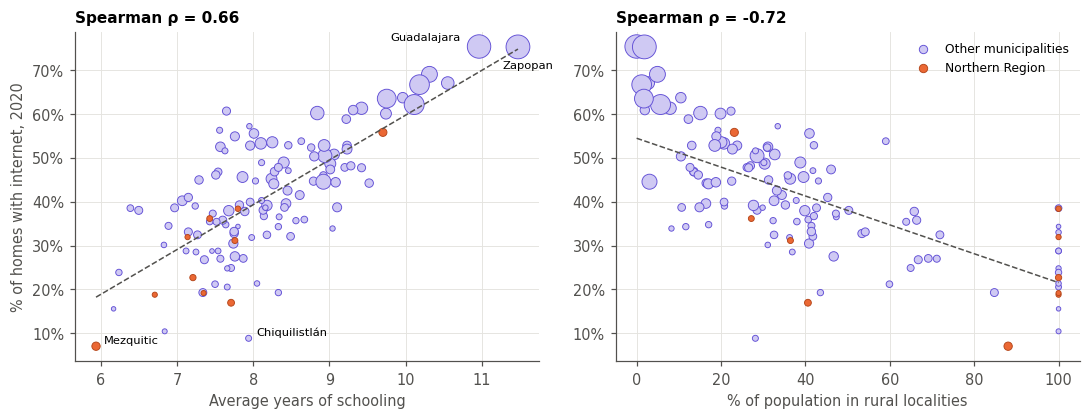

  figure: fig7_internet_drivers.png


In [74]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9))
lab, c20, c10 = IND["pct_internet"]
for ax, xv, xl in ((ax1, "graproes", "Average years of schooling"),
                   (ax2, "pct_pob_rural", "% of population in rural localities")):
    x, y = m20[xv], m20["pct_internet"]
    ax.scatter(x[~nor], y[~nor], s=np.sqrt(m20.pobtot[~nor]) / 5, color=c10, edgecolor=c20, lw=.6, label="Other municipalities")
    ax.scatter(x[nor], y[nor], s=np.sqrt(m20.pobtot[nor]) / 5, color="#eb6834", edgecolor="#b5461a", lw=.6, label="Northern Region")
    b1, b0 = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, b0 + b1 * xs, color=INK2, lw=1, ls="--")
    rs = x.corr(y, method="spearman")
    ax.set_xlabel(xl); ax.set_title(f"Spearman ρ = {rs:.2f}", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_ylabel("% of homes with internet, 2020")
for name, off in (("Guadalajara", (-58, 4)), ("Zapopan", (-10, -14)), ("Mezquitic", (5, 2)), ("Chiquilistlán", (5, 2))):
    i = m20.index[m20.nom_mun == name][0]
    ax1.annotate(name, (m20.graproes[i], m20.pct_internet[i]), xytext=off, textcoords="offset points", fontsize=7.5)
ax2.legend(fontsize=8, loc="upper right")
for h in ax2.get_legend().legend_handles: h.set_sizes([30])
fig.tight_layout()
guardar(fig, "fig7_internet_drivers.png")

### Table 2 · Correlations and outliers
Spearman correlations across municipalities and outliers by the interquartile range rule.

In [75]:
cols = {"pct_3servicios": "All three services", "pct_internet": "Internet"}
rows = {"pct_hli": "% Indigenous-language speakers", "pct_piso_tierra": "% dirt floor",
        "graproes": "Average years of schooling", "pct_pob_rural": "% population in rural localities",
        "pobtot": "Population (size)"}
t2 = pd.DataFrame({cols[c]: {rows[r]: m20[r].corr(m20[c], method="spearman") for r in rows} for c in cols}).round(2)
t2.to_csv(TAB / "table2_spearman_2020.csv")
print(t2.to_string())

# IQR outliers 2020 per indicator (names)
out = []
for v in V:
    s = m20.set_index("nom_mun")[v]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    for n, x in s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)].sort_values().items():
        out.append({"indicator": IND[v][0], "municipality": n, "value": round(x, 1),
                    "lower_fence": round(q1 - 1.5 * iqr, 1), "upper_fence": round(q3 + 1.5 * iqr, 1)})
pd.DataFrame(out).to_csv(TAB / "iqr_outliers_2020.csv", index=False)
print(pd.DataFrame(out).groupby("indicator").municipality.apply(lambda s: ", ".join(s.head(6))).to_string())
print("\nDone. Figures in", FIG.resolve(), "| tables in", TAB.resolve())

                                  All three services  Internet
% Indigenous-language speakers                 -0.05      0.04
% dirt floor                                   -0.57     -0.53
Average years of schooling                      0.67      0.66
% population in rural localities               -0.61     -0.72
Population (size)                               0.40      0.65
indicator
All three services    Mezquitic, Bolaños, Chimaltitán, Cuautitlán de...
Drainage              Mezquitic, Bolaños, Santa María del Oro, Cuaut...
Electricity           Mezquitic, Bolaños, Chimaltitán, Cuautitlán de...
Non-dirt floor        Mezquitic, Bolaños, Cuautitlán de García Barra...
Piped water           Mezquitic, Bolaños, San Cristóbal de la Barran...

Done. Figures in /content/drive/MyDrive/Proyecto_ITER_Jalisco/figures | tables in /content/drive/MyDrive/Proyecto_ITER_Jalisco/tables
